In [2]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

import datasets
import training_loop
import losses
import models

if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(device)

cuda


In [3]:
ef_reports = pd.read_csv("../labels/EF_reports.csv")
ef_reports = ef_reports.drop(columns=['MRN','SURGERY_DATE','JOINED_IMPRESSION','EF_post'])
ef_reports = ef_reports.dropna()

In [4]:
cycle1000 = pd.read_csv("../data/feedback_labeling/cycle_1000/predictions_all_cycle_1000.csv")
cycle2000 = pd.read_csv("../data/feedback_labeling/cycle_2000/predictions_all_cycle_2000.csv")
# cycle3000 = pd.read_csv("../data/feedback_labeling/cycle_3000/predictions_all_cycle_3000.csv")
cycle1000 = cycle1000.loc[cycle1000['prediction']==1]
cycle2000 = cycle2000.loc[cycle2000['prediction']==1]
# cycle3000 = cycle3000.loc[cycle3000['prediction']==1]

# cycle4000 = pd.read_csv("../data/feedback_labeling/cycle_4000/predictions_all_cycle_4000.csv")
# cycle4000 = cycle4000.loc[cycle4000['prediction']==1]

# train_cycles = pd.concat((cycle1000, cycle2000, ))
# test_cycles = cycle3000

train_cycles = cycle1000
test_cycles = cycle2000

In [5]:
# ef_reports = ef_reports.reset_index()
train_cycles = train_cycles.reset_index()
test_cycles = test_cycles.reset_index()

In [6]:
print(len(train_cycles))
removals = []
for i in range(len(train_cycles['clip_path'])):
    if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) not in list(ef_reports['ACC_NUM']):
        removals.append(i)
# for r in removals[::-1]:
#     train_cycles = train_cycles.drop(r)
train_cycles = train_cycles.drop(removals)
print(len(train_cycles))

print(len(test_cycles))
removals = []
for i in range(len(test_cycles['clip_path'])):
    if int(os.path.basename(os.path.split(test_cycles['clip_path'].iloc[i])[0])) not in list(ef_reports['ACC_NUM']):
        removals.append(i)
# for r in removals[::-1]:
#     test_cycles = test_cycles.drop(r)
test_cycles = test_cycles.drop(removals)
print(len(test_cycles))

train_cycles = train_cycles.reset_index()
test_cycles = test_cycles.reset_index()

4593
4431
5408
5243


In [7]:
train_clips = train_cycles['clip_path']
test_clips = test_cycles['clip_path']

In [8]:
train_transforms = datasets.TransformsComposed('train', size=(224,224))
valtest_transforms = datasets.TransformsComposed('valtest', size=(224,224))

In [9]:
train_dataset = datasets.VideoDataset(clip_paths=train_clips, labels_df=ef_reports, transform=train_transforms, duration=16, skip=2)
test_dataset = datasets.VideoDataset(clip_paths=test_clips, labels_df=ef_reports, transform=valtest_transforms, duration=16, skip=2)

In [113]:
# model = models.fetch_vit_model(
#         spatial_size = (224,224),
#         temporal_size = 16,
#         residual_pool = False,
#         residual_with_cls_embed = False,
#         stochastic_depth_prob = 0.0,
#         rel_pos_embed = True,
#         proj_after_attn = True,
#         num_classes = 1,
#     ).to(device)


model = models.fetch_s3d_model(
    num_classes = 1,
    dropout = 0.2,
).to(device)

# model = models.fetch_resnet_model(
#     num_classes = 1,
# ).to(device)




In [114]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0,)
# optimizer = torch.optim.Adam(model.parameters(), lr=0.00001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0,)

In [11]:
loss_fn = losses.SimpleLoss()

In [12]:
training_loop.simple_training_loop(
    run_dir             = '../experiments/test_s3d_224_32_1_0',  # Output directory.
    dataset             = train_dataset,                # Options for training set.
    validation_dataset  = test_dataset,                 # Options for training set.
    network             = model,                        # Options for model and preconditioning.
    loss                = loss_fn,                      # Options for loss function.
    optimizer           = optimizer,                    # Options for optimizer.
    seed                = 0,                            # Global random seed.
    batch_size          = 16,                           # Total batch size for one training iteration.
    num_workers         = 8,                            # Number of data loading workers.
    total_kimg          = 1000,                          # Training duration, measured in thousands of training images.
    kimg_per_tick       = 10,                           # How often to log training and validation stats.
    kimg_per_save       = 50,                           # How often to save the training state.
    device              = torch.device('cuda'),
)

Loading dataset...
Constructing network...
Setting up optimizer...
Setting up logs...
Training for 1000 kimg...

tick 625, loss 0.0735, std 0.1186, valloss 0.2426, valstd 0.1239, time 91.67 sec
tick 1250, loss 0.0560, std 0.0653, valloss 0.1673, valstd 0.1045, time 91.45 sec
tick 1875, loss 0.0519, std 0.0598, valloss 0.1573, valstd 0.0870, time 104.75 sec
tick 2500, loss 0.0482, std 0.0569, valloss 0.0798, valstd 0.0593, time 110.97 sec


In [10]:
model = torch.load('/home/trevor/repos/deep_TEE/experiments/test_s3d_224_32_1_0/training-state-001810.pt')['net'].to(device)
# model = torch.load('/home/trevor/repos/deep_TEE/experiments/test_64_64_04/training-state-002554.pt')['net'].to(device)

0.17648550868034363
0.575


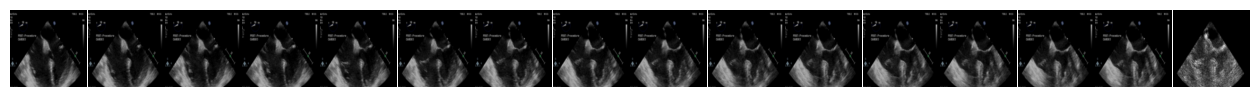

In [ ]:
# Visualize the images
idx = np.random.randint(len(train_dataset))
parcel = train_dataset[idx]['data']

with torch.no_grad():
    print(model(train_dataset[idx]['data'].unsqueeze(0).to(device)).item())
    print(train_dataset[idx]['label'])

fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
for i in range(parcel.shape[1]):
    ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
    ax[i].set_axis_off()
plt.subplots_adjust(wspace=0, hspace=0)

# Accumulated motion image
plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))

0.43818074464797974
0.275


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


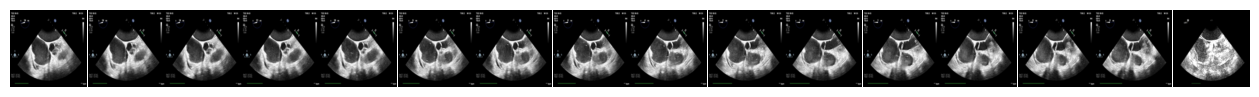

In [ ]:
# Visualize the images
idx = np.random.randint(len(test_dataset))
parcel = test_dataset[idx]['data']

with torch.no_grad():
    print(model(test_dataset[idx]['data'].unsqueeze(0).to(device)).item())
    print(test_dataset[idx]['label'])

fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
for i in range(parcel.shape[1]):
    ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
    ax[i].set_axis_off()
plt.subplots_adjust(wspace=0, hspace=0)

# Accumulated motion image
plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))

# Evaluation

In [10]:
model = torch.load('/home/trevor/repos/deep_TEE/experiments/s3d_224_16_2_0/training-state-002153.pt')['net'].to(device)
model = model.eval()

## No Aggregation

100%|██████████| 5243/5243 [04:38<00:00, 18.84it/s]


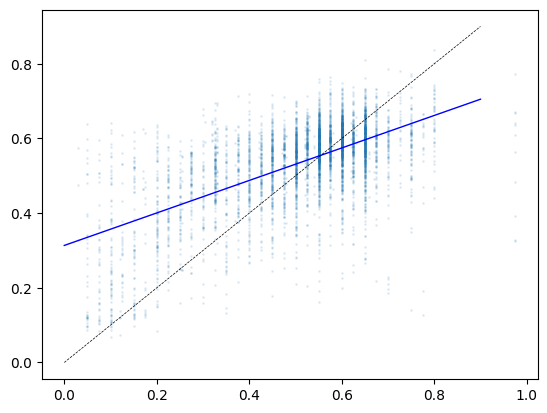

In [178]:
y = []
yp = []
maxsample = 10000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        if test_dataset[idx]['label'] != test_dataset[idx]['label']:
            continue
        if test_dataset[idx]['label'] > 1:
            continue
        y.append(test_dataset[idx]['label'])
        yp.append(model(test_dataset[idx]['data'].unsqueeze(0).to(device)).item())
df = pd.DataFrame({'y':y, 'yp':yp})

In [13]:
# y = []
# yp = []
# maxsample = 10000

# with torch.no_grad():
#     for idx in tqdm.tqdm(range(min(len(train_dataset), maxsample))):
#         if train_dataset[idx]['label'] != train_dataset[idx]['label']:
#             continue
#         y.append(train_dataset[idx]['label'])
#         yp.append(model(train_dataset[idx]['data'].unsqueeze(0).to(device)).item())

Logistic: ROC AUC=0.785
Logistic: ROC AUC=0.888


Text(0.5, 0.98, 'Predicting Left Ventricular Ejection Fraction')

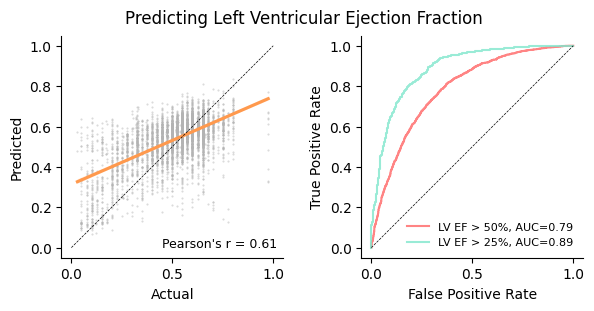

In [182]:
fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])

from scipy import stats
res = stats.pearsonr(y, yp)
sns.regplot(data=df, x="y", y="yp", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


y50 = [v > 0.5 for v in y]
y25 = [v > 0.25 for v in y]

testy, predy = y50, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

testy, predy = y25, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].legend(fontsize=8, frameon=False)
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')

plt.suptitle('Predicting Left Ventricular Ejection Fraction')

## Aggregation over a clip

In [13]:
class EvaluationDataset(torch.utils.data.Dataset):

    def __init__(self, clips, labels=None, transform=None, duration=32, skip=1, autobatch=True):
        self.clips = clips
        self.transform = transform
        self.duration = duration
        self.skip = skip
        self.autobatch = autobatch
        self.labels = labels

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):
        data = self.__read_images(self.clips[idx], self.duration, self.skip)
        
        if self.transform:
            data = self.transform(data)
            
        data = data.permute(0,2,1,3,4) # reshape to (B,C,T,H,W)
        
        if self.labels:
            label = labels[idx]
            return {'data':data, 'label':label}
        else:
            return {'data':data}
    
    def __read_images(self, path, duration=32, skip=1):
        frame_paths = glob.glob(path+'/*')
        if not self.autobatch:
            if len(frame_paths) <= duration * skip:
                start = 0
                stop = len(frame_paths)
                pad = (duration * skip - stop) // skip
            else:
                start = np.random.randint(0, len(frame_paths) - duration * skip + 1)
                stop = start + duration * skip
                pad = 0
            frames = []
            for frame in sorted(frame_paths)[start:stop:skip]:
                frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
            for i in range(pad):
                frames.append(torch.zeros_like(frames[-1]))
            frames = torch.stack(frames, dim=0)
            batches = frames
        else:
            batches = []
            for batch in range(int(np.ceil(len(frame_paths)/skip/duration))):
                start = batch * skip * duration
                stop = min((batch + 1) * skip * duration, len(frame_paths))
                pad = min(0, len(frame_paths) - ((batch + 1) * skip * duration))
                
                frames = []
                for frame in sorted(frame_paths)[start:stop:skip]:
                    frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
                for i in range(-pad//2):
                    frames.append(torch.zeros_like(frames[-1]))
                frames = torch.stack(frames, dim=0)
                batches.append(frames)
            batches = torch.stack(batches, dim=0)
        return batches

In [14]:
paths = [test_dataset.clip_paths[i] for i in range(len(test_dataset))]
labels = [test_dataset[i]['label'] for i in range(len(test_dataset))]

In [15]:
eval_dataset = EvaluationDataset(paths, labels=labels, transform=valtest_transforms, duration=16, skip=2, autobatch=True)

In [ ]:
y = []
yp = []
maxsample = 10000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
        y.append(eval_dataset[idx]['label'])
        yp.append(torch.mean(model(eval_dataset[idx]['data'].to(device))).item())
df = pd.DataFrame({'y':y, 'yp':yp})

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])

from scipy import stats
res = stats.pearsonr(y, yp)
sns.regplot(data=df, x="y", y="yp", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


y50 = [v > 0.5 for v in y]
y25 = [v > 0.25 for v in y]

testy, predy = y50, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

testy, predy = y25, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].legend(fontsize=8, frameon=False)
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')

plt.suptitle('Predicting Left Ventricular Ejection Fraction')

## Aggregation over an entire study

In [16]:
# Aggregation over time for one clip, but not for study

y = []
yp = []
maxsample = 10000
running_pred = []
running_label = []
curr_acc = os.path.basename(os.path.split(eval_dataset.clips[0])[0])

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
        acc = os.path.basename(os.path.split(eval_dataset.clips[idx])[0])
        if acc != curr_acc:
            y.append(np.mean(running_label))
            yp.append(np.mean(running_pred))
            running_pred = []
            running_label = []
            curr_acc = acc
        
        running_pred.append(torch.mean(model(eval_dataset[idx]['data'].to(device))).item())
        running_label.append(eval_dataset[idx]['label'])
        
df = pd.DataFrame({'y':y, 'yp':yp})

100%|██████████| 5243/5243 [04:17<00:00, 20.38it/s]


Logistic: ROC AUC=0.840
Logistic: ROC AUC=0.947


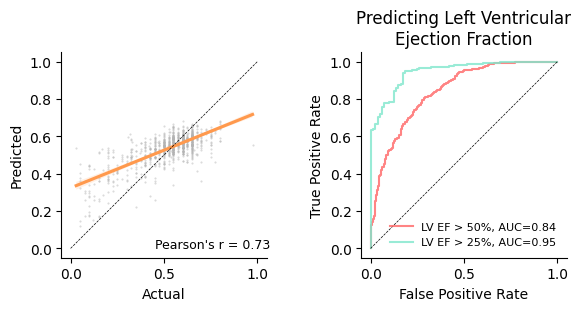

In [17]:
fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])

from scipy import stats
res = stats.pearsonr(y, yp)
sns.regplot(data=df, x="y", y="yp", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


y50 = [v > 0.5 for v in y]
y25 = [v > 0.25 for v in y]

testy, predy = y50, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

testy, predy = y25, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].legend(fontsize=8, frameon=False)
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')
ax[1].set_title('Predicting Left Ventricular\nEjection Fraction')

plt.savefig('LVEF_prediction.png',dpi=300)